# Retail Sales — Seaborn: Complete Beginner Graphs + Data Analysis

**22 runnable graphs + 12 worked pandas analyses.** Shared reproducible 2,400-row synthetic retail transactions (2025). Each graph is named and explained with purpose, code reading guidance, interpretation, cautions and business action. No object-oriented plotting syntax is required. Run all cells in order.

**Note:** This is a simulated, realistic retail scenario—not actual company sales.

In [13]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
products = {
    'Electronics': [('Headphones', 2400, .68), ('Smartwatch', 5500, .70), ('Speaker', 3200, .66), ('Tablet', 18500, .78)],
    'Fashion': [('T-Shirt', 899, .50), ('Jeans', 1899, .53), ('Jacket', 3499, .56), ('Shoes', 2599, .58)],
    'Home & Kitchen': [('Cookware', 2799, .59), ('Lamp', 1299, .55), ('Mixer', 4499, .70), ('Bedsheet', 1599, .51)],
    'Beauty': [('Skincare Kit', 1499, .49), ('Perfume', 2999, .54), ('Hair Dryer', 2199, .61), ('Face Wash', 599, .46)]
}
records = []
for i in range(2400):
    month = int(rng.choice(np.arange(1, 13), p=[.065,.065,.075,.07,.075,.075,.08,.08,.09,.11,.12,.095]))
    day = int(rng.integers(1, pd.Period(f'2025-{month:02d}').days_in_month + 1))
    category = str(rng.choice(list(products), p=[.32,.29,.25,.14]))
    product, price, cost_ratio = products[category][int(rng.integers(0, 4))]
    region = str(rng.choice(['North','South','East','West'], p=[.25,.34,.18,.23]))
    channel = str(rng.choice(['Online','Retail Store','Marketplace'], p=[.47,.31,.22]))
    units = int(rng.choice([1,2,3,4,5,6], p=[.46,.27,.14,.07,.04,.02]))
    discount = float(rng.choice([0,.05,.10,.15,.20,.25], p=[.25,.24,.20,.16,.10,.05]))
    revenue = round(units * price * (1 - discount), 2)
    cost = round(units * price * cost_ratio, 2)
    profit = round(revenue - cost, 2)
    delivery = int(max(1, round(rng.normal(3.8 if channel != 'Retail Store' else 1.5, 1.7))))
    rating = float(np.clip(round(rng.normal(4.1 - .07 * max(delivery-4, 0), .55), 1), 1, 5))
    records.append([f'ORD-{i+1:05d}', f'2025-{month:02d}-{day:02d}', region, category, product,
                    str(rng.choice(['Consumer','Corporate','Small Business'], p=[.64,.23,.13])),
                    channel, units, price, discount, revenue, cost, profit,
                    round(100 * profit/revenue, 2), delivery, rating])
columns = ['Order_ID','Order_Date','Region','Category','Product','Customer_Segment','Sales_Channel',
           'Units','Unit_Price','Discount_Pct','Revenue','Cost','Profit','Margin_Pct','Delivery_Days','Customer_Rating']
df = pd.DataFrame(records, columns=columns).sort_values('Order_Date').reset_index(drop=True)
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month_Num'] = df['Order_Date'].dt.month
df['Month'] = df['Order_Date'].dt.strftime('%b')
df['Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
print('Dataset shape:', df.shape)
print('Total revenue: ₹{:,.0f} | Total profit: ₹{:,.0f}'.format(df['Revenue'].sum(), df['Profit'].sum()))
df.head()



Dataset shape: (2400, 19)
Total revenue: ₹18,118,715 | Total profit: ₹4,466,321


,Order_ID,Order_Date,Region,Category,Product,Customer_Segment,Sales_Channel,Units,Unit_Price,Discount_Pct,Revenue,Cost,Profit,Margin_Pct,Delivery_Days,Customer_Rating,Month_Num,Month,Quarter
0,ORD-00190,2025-01-01,North,Fashion,T-Shirt,Consumer,Marketplace,1,899,0.1,809.1,449.50,359.60,44.44,5,3.4,1,Jan,Q1
1,ORD-00326,2025-01-01,North,Home & Kitchen,Cookware,Small Business,Retail Store,1,2799,0.0,2799.0,1651.41,1147.59,41.00,1,4.1,1,Jan,Q1
2,ORD-00432,2025-01-01,West,Home & Kitchen,Mixer,Consumer,Online,4,4499,0.0,17996.0,12597.20,5398.80,30.00,6,4.6,1,Jan,Q1
3,ORD-00836,2025-01-01,East,Fashion,Jacket,Corporate,Marketplace,3,3499,0.1,9447.3,5878.32,3568.98,37.78,4,3.2,1,Jan,Q1
4,ORD-00972,2025-01-01,South,Electronics,Speaker,Consumer,Retail Store,1,3200,0.1,2880.0,2112.00,768.00,26.67,1,4.6,1,Jan,Q1


In [21]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(45)
products = {
    'Electronics': [('Headphones', 2400, .68), ('Smartwatch', 5500, .70), ('Speaker', 3200, .66), ('Tablet', 18500, .78)],
    'Fashion': [('T-Shirt', 899, .50), ('Jeans', 1899, .53), ('Jacket', 3499, .56), ('Shoes', 2599, .58)],
    'Home & Kitchen': [('Cookware', 2799, .59), ('Lamp', 1299, .55), ('Mixer', 4499, .70), ('Bedsheet', 1599, .51)],
    'Beauty': [('Skincare Kit', 1499, .49), ('Perfume', 2999, .54), ('Hair Dryer', 2199, .61), ('Face Wash', 599, .46)]
}
record = []

for c in range(2400):
        month = int(rng.choice(np.arange(1, 13), p=[.065,.065,.075,.07,.075,.075,.08,.08,.09,.11,.12,.095]))
        day = int(rng.integers(1, pd.Period(f'2025-{month:02d}').days_in_month + 1))
        category = str(rng.choice(list(products), p=[.32,.29,.25,.14]))
        product, price, cost_ratio = products[category][int(rng.integers(0, 4))]
        region = str(rng.choice(['North','South','East','West'], p=[.25,.34,.18,.23]))
        channel = str(rng.choice(['Online','Retail Store','Marketplace'], p=[.47,.31,.22]))
        units = int(rng.choice([1,2,3,4,5,6], p=[.46,.27,.14,.07,.04,.02]))
        discount = float(rng.choice([0,.05,.10,.15,.20,.25], p=[.25,.24,.20,.16,.10,.05]))
        revenue = round(units * price * (1 - discount), 2)
        cost = round(units * price * cost_ratio, 2)
        profit = round(revenue - cost, 2)
        delivery = int(max(1, round(rng.normal(3.8 if channel != 'Retail Store' else 1.5, 1.7))))
        rating = float(np.clip(round(rng.normal(4.1 - .07 * max(delivery-4, 0), .55), 1), 1, 5))
        record.append([f'ORD-{i+1:05d}', f'2025-{month:02d}-{day:02d}', region, category, product,
                        str(rng.choice(['Consumer','Corporate','Small Business'], p=[.64,.23,.13])),
                        channel, units, price, discount, revenue, cost, profit,
                        round(100 * profit/revenue, 2), delivery, rating])
        columns = ['Order_ID','Order_Date','Region','Category','Product','Customer_Segment','Sales_Channel',
               'Units','Unit_Price','Discount_Pct','Revenue','Cost','Profit','Margin_Pct','Delivery_Days','Customer_Rating']
        
df = pd.DataFrame(record, columns =columns).sort_values('Order_Date').reset_index(drop = True)
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month_Num'] = df['Order_Date'].dt.month
df['Month'] = df['Order_Date'].dt.strftime('%b')
df['Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
print('Dataset shape:', df.shape)
print('Total revenue: ₹{:,.0f} | Total profit: ₹{:,.0f}'.format(df['Revenue'].sum(), df['Profit'].sum()))
df.head()
df.tail()



Dataset shape: (2400, 19)
Total revenue: ₹18,222,911 | Total profit: ₹4,505,059


,Order_ID,Order_Date,Region,Category,Product,Customer_Segment,Sales_Channel,Units,Unit_Price,Discount_Pct,Revenue,Cost,Profit,Margin_Pct,Delivery_Days,Customer_Rating,Month_Num,Month,Quarter
2395,ORD-02400,2025-12-31,South,Beauty,Hair Dryer,Consumer,Retail Store,4,2199,0.25,6597.0,5365.56,1231.44,18.67,1,4.0,12,Dec,Q4
2396,ORD-02400,2025-12-31,West,Electronics,Headphones,Consumer,Online,2,2400,0.15,4080.0,3264.00,816.00,20.00,3,4.0,12,Dec,Q4
2397,ORD-02400,2025-12-31,South,Beauty,Perfume,Small Business,Marketplace,2,2999,0.00,5998.0,3238.92,2759.08,46.00,5,4.2,12,Dec,Q4
2398,ORD-02400,2025-12-31,South,Electronics,Headphones,Consumer,Online,1,2400,0.00,2400.0,1632.00,768.00,32.00,2,4.5,12,Dec,Q4
2399,ORD-02400,2025-12-31,South,Electronics,Headphones,Corporate,Marketplace,1,2400,0.00,2400.0,1632.00,768.00,32.00,3,4.8,12,Dec,Q4


## How to read a business chart

**Business context:** You are a retail data analyst studying a fictional Indian retail business with 2,400 transactions in 2025. All values are generated examples, not observed real-world sales.

**Start with a question → choose a measure → group the data → plot → interpret → take action.** For example, “Which region is most profitable?” requires `groupby('Region')['Profit'].sum()`, not a count of records.

**Important measures:** `Revenue` is money received after discounts, `Cost` is estimated associated cost, `Profit = Revenue - Cost`, and `Margin_Pct = Profit / Revenue × 100` for each order. Overall business margin must be calculated as **total profit / total revenue**, not the simple mean of order margins.

**Graph-reading checklist:** (1) Identify the x and y variables and units. (2) Check whether the y-value is a sum, count, mean, or proportion. (3) Locate peaks, lows, exceptions and gaps. (4) Consider sample size, discounts and product mix. (5) Translate the pattern into a testable business action.

**Caution:** Correlation does not establish causation. A category with the highest sales is not automatically the most profitable. Charts from simulated data illustrate analysis techniques, not real market trends.


## Dataset overview and business questions

This sample mimics a multi-category Indian retailer selling through Online, Retail Store and Marketplace channels. **Revenue** is sales after discounts; **Profit = Revenue − Cost**. Values are in Indian rupees (₹).

- Orders: **2,400**; annual revenue: **₹18,118,715**; annual profit: **₹4,466,321**.
- Top category by revenue: **Electronics** (₹11,460,200).
- Highest-revenue month: **November** (₹2,543,583).
- Leading channel by revenue: **Online** (48.3% of total).

> Learning note: These findings describe the **generated practice dataset**, not an actual retailer. A graph shows associations and patterns; it does not prove causation.

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
%matplotlib inline

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
%matplotlib inline

## 01. Lineplot — monthly sales trend

**Purpose:** Identify high and low revenue months.

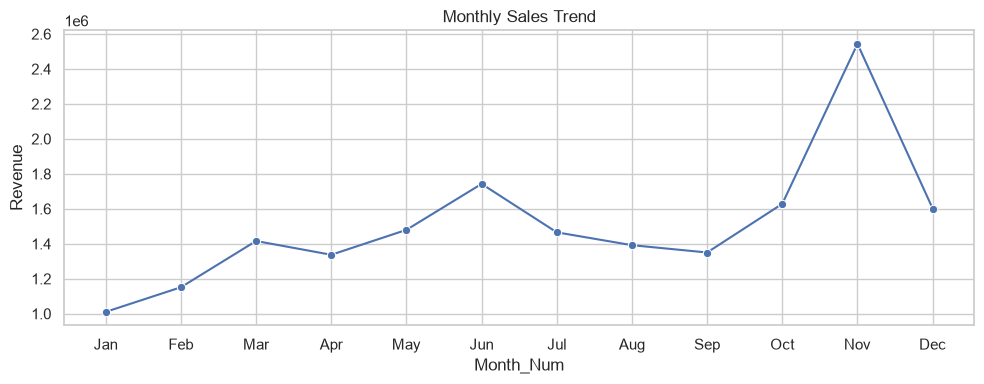

In [6]:
monthly = df.groupby('Month_Num', as_index=False)['Revenue'].sum()
plt.figure(figsize=(10, 4))
sns.lineplot(data=monthly, x='Month_Num', y='Revenue', marker='o')
plt.xticks(range(1,13), month_order)
plt.title('Monthly Sales Trend'); plt.tight_layout(); plt.show()

**Outcome:** Peak sales occur in **November**.

**Suggested business decision:** Use sales trends for monthly operational planning.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 02. Barplot — average order value by category

**Purpose:** Compare typical order values across categories.

In [ ]:
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x='Category', y='Revenue', estimator='mean', errorbar=None, color='steelblue')
plt.title('Average Order Revenue by Category'); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

**Outcome:** **Electronics** has the highest average order revenue.

**Suggested business decision:** Consider bundles to grow lower-value categories.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 03. Countplot — orders by region

**Purpose:** Compare order volumes, rather than money, across regions.

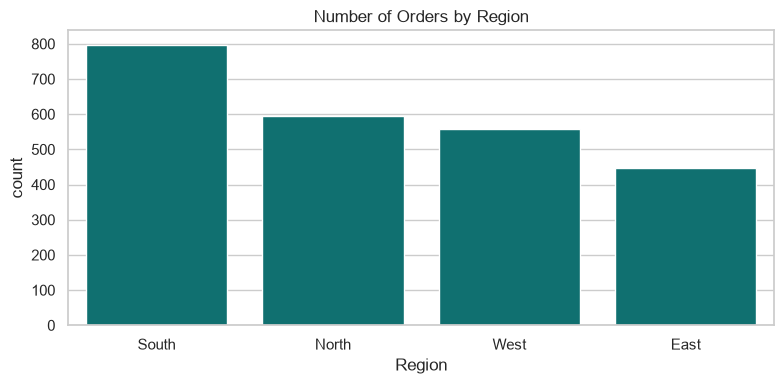

In [7]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Region', order=df['Region'].value_counts().index, color='teal')
plt.title('Number of Orders by Region'); plt.tight_layout(); plt.show()

**Outcome:** **South** produces the highest number of orders (798).

**Suggested business decision:** Compare demand volume with warehouse coverage.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 04. Histplot — distribution of order revenue

**Purpose:** Understand skew and common transaction sizes.

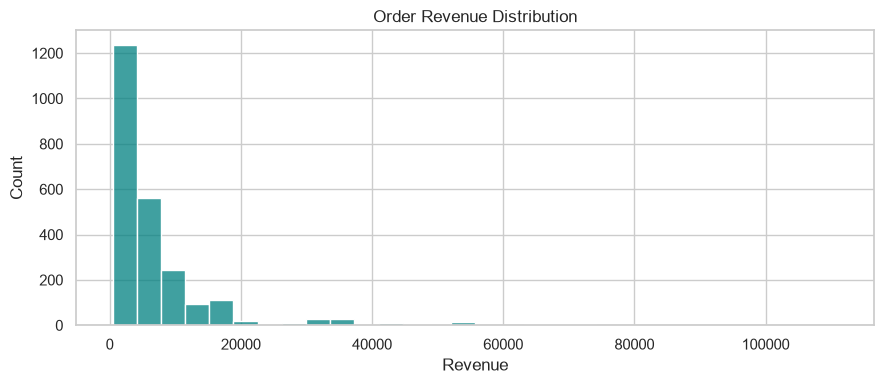

In [8]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x='Revenue', bins=30, color='teal')
plt.title('Order Revenue Distribution'); plt.tight_layout(); plt.show()

**Outcome:** Half of orders are below **₹3,897**.

**Suggested business decision:** Design offers around actual basket size distribution.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 05. KDE plot — revenue density by channel

**Purpose:** Compare smoothed order-value distributions.

In [ ]:
plt.figure(figsize=(9, 4))
sns.kdeplot(data=df, x='Revenue', hue='Sales_Channel', fill=False, common_norm=False)
plt.title('Order Value Density by Channel'); plt.tight_layout(); plt.show()

**Outcome:** Density peaks help compare common transaction values across channels; curves show distributions, not total sales.

**Suggested business decision:** Use channel-level basket analyses to tailor campaigns.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 06. Scatterplot — discounts and margins by category

**Purpose:** Examine discounts and margins with category colors.

In [ ]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Discount_Pct', y='Margin_Pct', hue='Category', alpha=.55, s=25)
plt.title('Discount vs Margin by Category'); plt.tight_layout(); plt.show()

**Outcome:** The synthetic price model causes profit margins to decline as discounts rise; categories have different cost bases.

**Suggested business decision:** Review discount policy by category rather than universally.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 07. Boxplot — profit distribution by category

**Purpose:** Compare median profit, variation and outliers.

In [ ]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x='Category', y='Profit', color='skyblue')
plt.title('Order Profit by Category'); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

**Outcome:** Highest median order profit belongs to **Electronics**.

**Suggested business decision:** Do not confuse order-level profit with category total profit.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 08. Violinplot — delivery days by channel

**Purpose:** See delivery speed and its distribution shape.

In [ ]:
plt.figure(figsize=(9, 4))
sns.violinplot(data=df, x='Sales_Channel', y='Delivery_Days', inner='quartile', color='plum')
plt.title('Delivery Time Distribution'); plt.tight_layout(); plt.show()

**Outcome:** Retail Store has shorter fulfilment times in this synthetic sample.

**Suggested business decision:** Set service-level targets appropriate to the channel.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 09. Heatmap — region versus category revenue

**Purpose:** Find high-performing category-region combinations.

In [ ]:
pivot = df.pivot_table(index='Region', columns='Category', values='Revenue', aggfunc='sum', fill_value=0)
plt.figure(figsize=(10, 4))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Blues')
plt.title('Revenue by Region and Category'); plt.tight_layout(); plt.show()

**Outcome:** Dark cells represent category-region combinations with greater sales revenue.

**Suggested business decision:** Allocate merchandising attention at regional-category level.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 10. Stripplot — customer ratings by channel

**Purpose:** Display individual feedback scores by channel.

In [ ]:
plt.figure(figsize=(9, 4))
sns.stripplot(data=df.sample(450, random_state=42), x='Sales_Channel', y='Customer_Rating', jitter=.25, alpha=.35)
plt.title('Customer Ratings by Channel (Sample)'); plt.tight_layout(); plt.show()

**Outcome:** The overall average rating is **4.07/5**.

**Suggested business decision:** Use customer-feedback distributions to locate service issues.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 11. Pointplot — average profit margin by region

**Purpose:** Compare regional average margins.

In [ ]:
plt.figure(figsize=(9, 4))
sns.pointplot(data=df, x='Region', y='Margin_Pct', errorbar=None, markers='o', color='seagreen')
plt.title('Average Order Margin by Region'); plt.ylabel('Margin (%)')
plt.tight_layout(); plt.show()

**Outcome:** The highest average order margin is in **West**.

**Suggested business decision:** Compare margin performance separately from total revenue.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 12. Regplot — units versus order revenue

**Purpose:** Visualize association between units sold and order revenue.

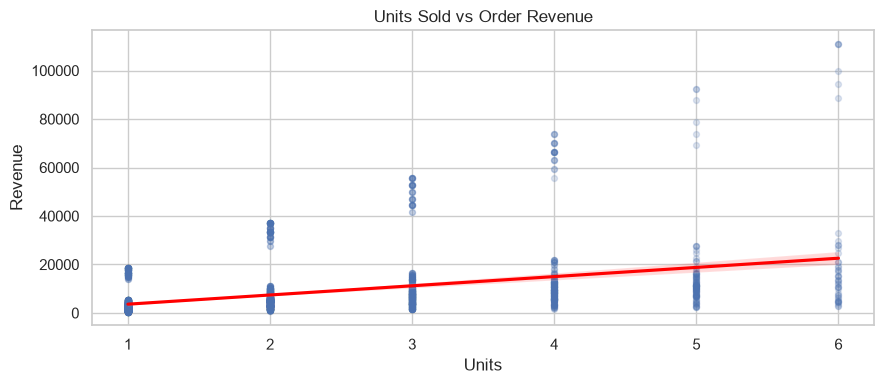

In [12]:
plt.figure(figsize=(9, 4))
sns.regplot(data=df, x='Units', y='Revenue', scatter_kws={'alpha':.18, 's':18}, line_kws={'color':'red'})
plt.title('Units Sold vs Order Revenue'); plt.tight_layout(); plt.show()

**Outcome:** Orders with more units often generate more revenue, but product prices create substantial variation.

**Suggested business decision:** Consider units and product mix together when forecasting.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## Part B — Additional basic and practical graphs

These ten charts add common beginner-friendly and industry-useful chart families. For each, learn when to use it, what the plotted variable represents, and which business action it might support.

### 13. Swarmplot — ratings by region

**Purpose:** Visualize individual ratings without overlapping dots.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [3]:
sample = df.sample(250, random_state=7)
plt.figure(figsize=(9,4)); sns.swarmplot(data=sample, x='Region', y='Customer_Rating', size=3)
plt.title('Sample Customer Ratings by Region'); plt.show()

NameError: name 'plt' is not defined

**Interpretation:** Shows granular observations; a small random sample is used to keep the plot readable.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 14. Rugplot — order values

**Purpose:** Mark every observation along a one-dimensional axis.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
plt.figure(figsize=(10,3)); sns.rugplot(data=df.sample(350,random_state=7), x='Revenue', height=.2)
plt.title('Sample Order Revenue Values'); plt.xlabel('Revenue (₹)'); plt.show()

**Interpretation:** Dense rug marks show typical value ranges; this plot is most useful with a manageable sample.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 15. ECDF plot — order value thresholds

**Purpose:** Read the percentage of orders at or below a given rupee value.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
plt.figure(figsize=(9,4)); sns.ecdfplot(data=df, x='Revenue', hue='Sales_Channel')
plt.xlabel('Order revenue (₹)'); plt.title('Cumulative Proportion of Order Values'); plt.show()

**Interpretation:** At any x-value, the y-value is the share of orders whose revenue is less than or equal to that value.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 16. Jointplot — unit price and revenue

**Purpose:** Study a relationship together with the individual variable distributions.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
sns.jointplot(data=df.sample(500,random_state=7), x='Unit_Price', y='Revenue', kind='scatter', height=6)
plt.show()

**Interpretation:** The marginal distributions reveal skew while the center shows how order revenue changes with price.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 17. Pairplot — multiple numerical relationships

**Purpose:** Quickly inspect pairwise relationships and distributions.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
subset = df.sample(180,random_state=7)[['Units','Discount_Pct','Margin_Pct','Revenue','Category']]
sns.pairplot(subset, hue='Category', corner=True, diag_kind='hist')
plt.show()

**Interpretation:** Pairplots are exploratory; use fewer rows and variables to avoid clutter and slow rendering.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 18. Catplot — region and channel order counts

**Purpose:** Compare counts within regions, split by sales channel.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
sns.catplot(data=df, x='Region', hue='Sales_Channel', kind='count', height=4, aspect=1.8)
plt.title('Order Counts by Region and Channel'); plt.show()

**Interpretation:** Counts tell you where volume comes from; they do not indicate average basket value or profitability.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 19. FacetGrid — channel-specific revenue histograms

**Purpose:** Compare the same distribution across channel panels.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
g = sns.FacetGrid(df, col='Sales_Channel', col_wrap=2, height=3)
g.map_dataframe(sns.histplot, x='Revenue', bins=20)
g.set_axis_labels('Order revenue (₹)','Orders')
plt.show()

**Interpretation:** Keeping separate panels can reveal large-value orders in some channels that are hidden in an overall histogram.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 20. Clustermap — category and region revenue

**Purpose:** Group categories and regions with similar sales patterns.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
matrix = df.pivot_table(index='Category', columns='Region', values='Revenue', aggfunc='sum', fill_value=0)
sns.clustermap(matrix, standard_scale=0, cmap='YlGnBu', annot=False, figsize=(8,6))
plt.show()

**Interpretation:** Values are scaled within each row for comparability; patterns of relative strength matter more than absolute revenue in this chart.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 21. Boxenplot — order value by channel

**Purpose:** Compare the tails of skewed revenue distributions.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
plt.figure(figsize=(9,4)); sns.boxenplot(data=df, x='Sales_Channel', y='Revenue')
plt.xticks(rotation=15); plt.title('Order Revenue Distribution by Channel'); plt.show()

**Interpretation:** This is useful for large or skewed datasets because it shows more distribution detail than a basic box plot.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 22. Barplot with hue — profit by region and channel

**Purpose:** Compare average order profit across two categories.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

In [ ]:
plt.figure(figsize=(10,4)); sns.barplot(data=df, x='Region', y='Profit', hue='Sales_Channel', errorbar=None)
plt.title('Mean Order Profit by Region and Channel'); plt.ylabel('Mean profit per order (₹)'); plt.show()

**Interpretation:** This graph displays mean profit per order, not total profit. A low-volume channel can have a high average.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

## Part C — Hands-on retail data analysis with pandas

The next twelve worked examples go beyond plotting. They show how a business analyst checks raw data, calculates KPIs, groups records, examines exceptions, and turns results into recommendations. Run each cell and inspect the output.

### Analysis 01 — Data quality and structure

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
# Review dataset size, sample rows, data types and missing values
print('Rows, columns:', df.shape)
display(df.head(5))
print('Duplicate order IDs:', df['Order_ID'].duplicated().sum())
print('Missing values by field:')
print(df.isna().sum().to_string())
print('Data types:')
print(df.dtypes.to_string())

**How to explain the outcome:** Check for duplicated IDs, invalid types and missing values before making a chart. A chart based on incomplete transactions can mislead management.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 02 — Core business KPIs

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()
orders = df['Order_ID'].nunique()
units_sold = df['Units'].sum()
kpis = pd.DataFrame({'Metric': ['Total revenue', 'Total profit', 'Total orders', 'Units sold', 'Average order value', 'Weighted profit margin (%)'], 'Value': [round(total_revenue,2), round(total_profit,2), orders, units_sold, round(total_revenue/orders,2), round(100*total_profit/total_revenue,2)]})
display(kpis)

**How to explain the outcome:** Sales value, profitability, units, order count and order value answer different management questions. Weighted margin uses total revenue as its denominator.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 03 — Category sales, margin and order volume

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
category_summary = df.groupby('Category').agg(Orders=('Order_ID','nunique'), Units=('Units','sum'), Revenue=('Revenue','sum'), Profit=('Profit','sum')).sort_values('Revenue', ascending=False)
category_summary['Margin_Pct'] = (100*category_summary['Profit']/category_summary['Revenue']).round(2)
category_summary['Avg_Order_Value'] = (category_summary['Revenue']/category_summary['Orders']).round(2)
display(category_summary.round(2))

**How to explain the outcome:** Compare revenue rank with margin and profit rank. Higher revenue may reflect premium-priced items, not superior efficiency.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 04 — Monthly growth and seasonality

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
month_summary = df.groupby(['Month_Num','Month'], as_index=False).agg(Revenue=('Revenue','sum'), Profit=('Profit','sum'), Orders=('Order_ID','count')).sort_values('Month_Num')
month_summary['Growth_Pct'] = month_summary['Revenue'].pct_change().mul(100).round(2)
month_summary['Profit_Margin_Pct'] = (100*month_summary['Profit']/month_summary['Revenue']).round(2)
display(month_summary)

**How to explain the outcome:** Month-on-month growth explains changes relative to the prior month. The first month has no prior-month comparison, so its growth is missing.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 05 — Region and channel performance

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
region_channel = df.pivot_table(index='Region', columns='Sales_Channel', values='Revenue', aggfunc='sum', fill_value=0)
region_channel['All_Channels'] = region_channel.sum(axis=1)
display(region_channel.round(2))
print('Top region by revenue:', region_channel['All_Channels'].idxmax())

**How to explain the outcome:** Use cross-tabulation to identify where a channel contributes most. Large revenue alone does not tell you the cost or margin of serving that market.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 06 — Top products and Pareto contribution

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
product_revenue = df.groupby('Product')['Revenue'].sum().sort_values(ascending=False)
product_share = pd.DataFrame({'Revenue': product_revenue})
product_share['Share_Pct'] = (product_share['Revenue']/product_share['Revenue'].sum()*100).round(2)
product_share['Cumulative_Share_Pct'] = product_share['Share_Pct'].cumsum().round(2)
display(product_share.head(10))

**How to explain the outcome:** Use the cumulative share to find whether a few products drive most revenue. The 80/20 rule is a hypothesis to test, not a guaranteed outcome.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 07 — Discount effectiveness and profitability

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
df['Discount_Band'] = pd.cut(df['Discount_Pct'], bins=[-0.001,0,0.05,0.10,0.15,1], labels=['0%','0–5%','5–10%','10–15%','15%+'])
discount_summary = df.groupby('Discount_Band', observed=True).agg(Orders=('Order_ID','count'), Revenue=('Revenue','sum'), Profit=('Profit','sum'))
discount_summary['Weighted_Margin_Pct'] = (100*discount_summary['Profit']/discount_summary['Revenue']).round(2)
display(discount_summary.round(2))

**How to explain the outcome:** Compare discounts with weighted margins and sample sizes. These observational comparisons do not prove discounts caused a sales increase.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 08 — Customer segment and average order value

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
segment_summary = df.groupby('Customer_Segment').agg(Orders=('Order_ID','count'), Revenue=('Revenue','sum'), Avg_Units=('Units','mean'), Avg_Rating=('Customer_Rating','mean'))
segment_summary['Avg_Order_Value'] = segment_summary['Revenue']/segment_summary['Orders']
display(segment_summary.round(2))

**How to explain the outcome:** Segments can produce similar revenue but different basket sizes. Plan promotions only after checking order count and product mix.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 09 — Delivery speed and customer feedback

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
df['Delivery_Group'] = pd.cut(df['Delivery_Days'], bins=[-1,2,4,7,100], labels=['0–2 days','3–4 days','5–7 days','8+ days'])
delivery_summary = df.groupby('Delivery_Group', observed=True).agg(Orders=('Order_ID','count'), Avg_Rating=('Customer_Rating','mean'), Avg_Revenue=('Revenue','mean'))
display(delivery_summary.round(2))

**How to explain the outcome:** Determine whether longer delivery groups have lower average ratings. This is descriptive, not a controlled causal test.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 10 — Find exceptions and potential anomalies

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
print('Orders with negative profit:', (df['Profit'] < 0).sum())
print('Largest orders by revenue:')
display(df.nlargest(5, 'Revenue')[['Order_ID','Category','Product','Revenue','Profit','Units','Discount_Pct']])
print('Lowest margin orders:')
display(df.nsmallest(5, 'Margin_Pct')[['Order_ID','Product','Revenue','Profit','Margin_Pct']])

**How to explain the outcome:** Investigate outliers before excluding them; unusually large transactions may be real wholesale purchases or data issues.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 11 — Correlation checks

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
numeric_cols = ['Units','Unit_Price','Discount_Pct','Revenue','Profit','Margin_Pct','Delivery_Days','Customer_Rating']
corr_table = df[numeric_cols].corr(numeric_only=True)
display(corr_table.round(2))

**How to explain the outcome:** Correlation ranges from -1 to +1. It describes linear association, not why a variable changes. Some relationships arise mechanically from how synthetic columns were generated.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 12 — Mini case study: business recommendations

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
best_category = category_summary['Profit'].idxmax()
peak_month_row = month_summary.loc[month_summary['Revenue'].idxmax()]
fastest_channel = df.groupby('Sales_Channel')['Delivery_Days'].median().idxmin()
print('Highest total-profit category:', best_category)
print('Highest sales month:', peak_month_row['Month'])
print('Fastest median delivery channel:', fastest_channel)
print('Suggested validation: compare category stockouts, monthly promotional calendars and channel fulfilment costs before acting.')

**How to explain the outcome:** A strong analyst ends with an action and a validation plan, not a chart alone. Check whether the observed pattern remains after accounting for order counts and mix.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

## Practice assignments

1. Filter the dataset to the **South** region and remake any three charts.
2. Compare **revenue versus profit** and identify why they differ.
3. Replace total revenue with **average order revenue** in one graph.
4. Explore whether higher discounts coincide with lower margins, **without claiming causation**.
5. Add labels, change colors and write two sentences explaining each chart.

**Final reminder:** All data is synthetic; code is intentionally beginner-friendly and uses no `ax` syntax.

## Final student project — Retail sales presentation

1. Calculate revenue, profit, margin, order count and average order value.
2. Pick five different graphs: time trend, category comparison, distribution, relationship and region-by-channel analysis.
3. Under each plot, write: **Question → Metric → Observation → Business decision → Caveat.**
4. Compare the strongest revenue category with the strongest margin category.
5. Explain why high discount orders may have different margins and what extra data is needed for a causal conclusion.
6. Present three prioritized recommendations with numbers from the analysis tables.

**Knowledge check:** When should you use a line plot instead of a bar chart? How do revenue share and order share differ? When does a median describe sales better than a mean? Why must overall margin be weighted? What is misleading about truncated axes or unlabelled normalization?